# Figures and tables for Pedal Poll 2024 paper

## Load and merge data

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import matplotlib
import matplotlib.cm as cm
from matplotlib import rcParams
rcParams['axes.prop_cycle'] = matplotlib.cycler(color=cm.viridis(np.linspace(0.1,1,3))) 
matplotlib.rcParams.update({'font.size': 10})

In [2]:
agg_counts = pd.read_csv("data/aggregated_data.csv")

In [3]:
canbics = pd.read_csv("data/PP_CounterPoints_Cycle_Facilities_FULL_02JAN2025.csv")
canbics['can_bics_facility'] = canbics['can_bics_facility'].str.strip() # remove leading spaces

In [4]:
# Change North Vancouver to Vancouver
agg_counts.loc[agg_counts['geocoded_city'] == 'North Vancouver', 'geocoded_city'] = 'Vancouver'

In [5]:
agg_counts['count_year'] = agg_counts['year']

In [6]:
agg_counts.shape

(1860, 29)

In [7]:
agg_counts = agg_counts.merge(canbics[['grouped_counterpoint_id', 'count_year', 
                                       'can_bics_facility', 'comfort_class', 'other_cycle_facility',
                                       'google_street_month', 'google_street_year']].drop_duplicates(),
                 on = ('grouped_counterpoint_id', 'count_year'), how = 'left')

In [8]:
agg_counts.shape

(1860, 34)

In [9]:
agg_counts['geocoded_province'].unique()

array(['Manitoba', 'Alberta', 'Ontario', 'Saskatchewan', 'Nova Scotia',
       'New Brunswick / Nouveau-Brunswick', 'British Columbia',
       'Newfoundland and Labrador', 'Prince Edward Island', 'Yukon',
       'Quebec', 'BC', 'Northwest Territories', 'New Brunswick'],
      dtype=object)

In [10]:
agg_counts.loc[(agg_counts['geocoded_province'] == 'New Brunswick / Nouveau-Brunswick'), 'geocoded_province'] = "New Brunswick"
agg_counts.loc[(agg_counts['geocoded_province'] == 'BC'), 'geocoded_province'] = "British Columbia"

In [11]:
agg_counts['bikes_per_hour'] = (agg_counts['bike_total'] / agg_counts['total_time_seconds'])*3600

In [12]:
agg_counts.shape

(1860, 35)

#### Pivot data

In [13]:
agg_counts['weekday_weekend'] = agg_counts['count_session_label'].str.split('_', expand = True)[0]

In [14]:
# average across all communities, regardless of repeated sites
weekday_weekend_averages = agg_counts.groupby(['weekday_weekend', 'year']).agg(mean = ('bikes_per_hour', 'mean'),
                                                                               std = ('bikes_per_hour', 'std'),
                                                                               count = ('bikes_per_hour', 'nunique')).reset_index()

weekday_weekend_averages = weekday_weekend_averages[weekday_weekend_averages['weekday_weekend'] != 'not'] # remove 'not_assigned' sessions

In [15]:
# pivot to make plotting easier
agg_counts_pivot = pd.pivot_table(agg_counts[['year', 'grouped_counterpoint_id', 'geocoded_city', 'geocoded_province',
       'count_session_label', 'weekday_weekend', 'bike_total', 'bikes_per_hour']],
               values = ['bike_total', 'bikes_per_hour'], index = ['grouped_counterpoint_id', 'geocoded_city', 
                                                                   'geocoded_province', 'count_session_label','weekday_weekend'],
               columns = 'year').reset_index()

In [16]:
# counts in every year of the first three years
agg_counts_pivot_threeyear = agg_counts_pivot[np.sum(agg_counts_pivot['bike_total'][[2021, 2022, 2023]].isna(), axis = 1) == 0]

In [17]:
# counts in every year
agg_counts_pivot_allyears = agg_counts_pivot[np.sum(agg_counts_pivot['bike_total'].isna(), axis = 1) == 0]

In [18]:
num_years = 4
# need at least two counts in the bike_total column to be a multi-year count. Number of NAs should be 2 or less
agg_counts_pivot_multiyear = agg_counts_pivot[np.sum(agg_counts_pivot['bike_total'].isna(), axis = 1) < (num_years - 1)]

In [19]:
# number of multi-year count sites
agg_counts_pivot_multiyear[agg_counts_pivot_multiyear['count_session_label'] != 'not_assigned'].shape

(443, 13)

## Summary table

- summarize infrastructure
- as in first paper: totals by province, total communities, total count time

In [20]:
num_sessions = agg_counts[agg_counts['count_session_label'] != 'not_assigned'].groupby(['year', 'grouped_counterpoint_id', 'count_session_label', 'start_datetime_dayofmonth'])['bike_total'].count().reset_index()

In [21]:
num_sessions.shape

(1806, 5)

In [22]:
agg_counts['geocoded_city'].unique()

array(['Winnipeg', 'Edmonton', 'Toronto', 'Saskatoon', 'Halifax',
       'Peterborough', 'Red Deer', 'Moncton', 'Ottawa', 'Campbell River',
       'Vancouver', 'Calgary', "St. John's", 'Burlington',
       'Charlottetown', 'North Dumfries', 'Kingston', 'Wolfville',
       'Mississauga', 'London', 'New Glasgow', 'Medicine Hat',
       'Whitehorse', 'Kitchener', 'Waterloo', 'Township of Langley',
       'Glace Bay', 'Victoria', 'Gatineau', 'Stratford',
       'Area E (Elphinstone)', 'Fredericton', 'Quebec City', 'Brampton',
       'Kamloops', 'Maple Ridge', 'Guelph', 'Kelowna', 'Oakville',
       'Orillia', 'Montreal', 'Stouffville', 'Windsor', 'Sarnia',
       'St. Catharines', 'Champlain', 'Regina', 'Sechelt', 'Lunenburg',
       'Coldbrook', 'Hamilton', 'Head of Chezzetcook', 'Bridgewater',
       'Area D (Roberts Creek)', 'Yellowknife', 'Saint John', 'Nelson',
       'No city', 'Banff', 'Canmore', 'Elliot Lake', 'Corner Brook',
       'Area H (The Slocan Valley)', 'Richmond'], dtype=

In [23]:
agg_counts['grouped_counterpoint_id'].unique().shape

(430,)

In [24]:
agg_counts['bike_total'].sum()

np.int64(205308)

In [25]:
agg_counts[agg_counts['count_session_label'] != 'not_assigned']['bike_total'].sum()

np.int64(201331)

In [26]:
agg_counts['geocoded_city'].unique().shape

(64,)

In [27]:
for year in [2021, 2022, 2023, 2024]:
    tot_bikes = agg_counts[agg_counts['year'] == year]['bike_total'].sum()
    tot_locations = agg_counts[agg_counts['year'] == year]['grouped_counterpoint_id'].unique().shape[0]
    tot_communities = agg_counts[agg_counts['year'] == year]['geocoded_city'].unique().shape[0]
    tot_hours = round(agg_counts[agg_counts['year'] == year]['total_time_seconds'].sum() / 3600, 1)
    print(year, tot_bikes, " bikes counted in ", tot_locations, " locations in ", tot_communities, " communities, ", tot_hours, " hours, and ",
         num_sessions[num_sessions['year'] == year].shape[0], " sessions.")

2021 79735  bikes counted in  266  locations in  53  communities,  1171.3  hours, and  654  sessions.
2022 49275  bikes counted in  223  locations in  39  communities,  870.2  hours, and  485  sessions.
2023 29083  bikes counted in  167  locations in  33  communities,  514.7  hours, and  300  sessions.
2024 47215  bikes counted in  167  locations in  31  communities,  683.8  hours, and  367  sessions.


In [28]:
summary_table = agg_counts.groupby(["geocoded_province", "year"])[["bike_total", "total_time_seconds"]].sum().reset_index()

In [29]:
summary_table['total_time_hours'] = round(summary_table['total_time_seconds'] / 3600,0)

In [30]:
summary_table_pivot = pd.pivot_table(summary_table[['geocoded_province',
       'bike_total', 'total_time_hours', 'year']],
               values = ['bike_total', 'total_time_hours'], index = ['geocoded_province'],
               columns = 'year').reset_index()

In [31]:
summary_table_pivot = summary_table_pivot.fillna(0)

In [32]:
summary_table_pivot['bike_total'] = summary_table_pivot['bike_total'].astype('int')
summary_table_pivot['total_time_hours'] = summary_table_pivot['total_time_hours'].astype('int')

In [33]:
summary_table_pivot['total_hours'] = summary_table_pivot['total_time_hours'].sum(axis = 1)

Note: the total counts are the same for 2021 as reported in the paper, but the total time in hours is off by 1 or 2 hours in most cases. I don't know why this is, I checked if it was a rounding error propagating and that doesn't seem quite right. Possibly go back to the 2021 reported data and check.

In [34]:
summary_table = summary_table_pivot.sort_values(by = 'total_hours', ascending = False)

summary_table = summary_table[['geocoded_province', 'bike_total', 'total_time_hours']]

In [35]:
summary_table

geocoded_province bike_total                       \
year                                  2021   2022   2023   2024   
7                       Ontario      29975  18220  14225  19197   
0                       Alberta       3258   4617   3115   3247   
1              British Columbia      31150  17815   5845  10042   
6                   Nova Scotia       2372   1710    867   1672   
2                      Manitoba       4419   2496   1308   1341   
10                 Saskatchewan       1812   1615   1215    644   
11                        Yukon        714    367    675   1097   
4     Newfoundland and Labrador        368    103     20      1   
8          Prince Edward Island        296    185    112    229   
9                        Quebec       4794   1601   1664   8333   
3                 New Brunswick        577    493     37    442   
5         Northwest Territories          0     53      0    970   

     total_time_hours                 
year             2021 2022 2023 2024  
7                 494  378  285  331  
0                  99  166   53   82  
1                 178  111   50   56  
6                 122   64   41   58  
2                 102   35   17   26  
10                 44   36   17   31  
11                 30   19   26   31  
4                  40   20    6    1  
8                  22   10   11   15  
9                  20   16    4   12  
3                  20   12    4   11  
5                   0    2    0   31

### Figure 1: total bikes counted and hours counted

In [36]:
summary_table.columns = summary_table.columns.get_level_values(0)

In [37]:
summary_table.columns = ['geocoded_province',        'bike_total_2021',        'bike_total_2022',
              'bike_total_2023',        'bike_total_2024',  'total_time_hours_2021',
        'total_time_hours_2022',  'total_time_hours_2023',  'total_time_hours_2024']

In [38]:
markers = ['o','x','s','^']

In [39]:
colors = sns.color_palette('husl', 12)
colors = np.concatenate([colors[::2], colors[1::2]]) # alternate

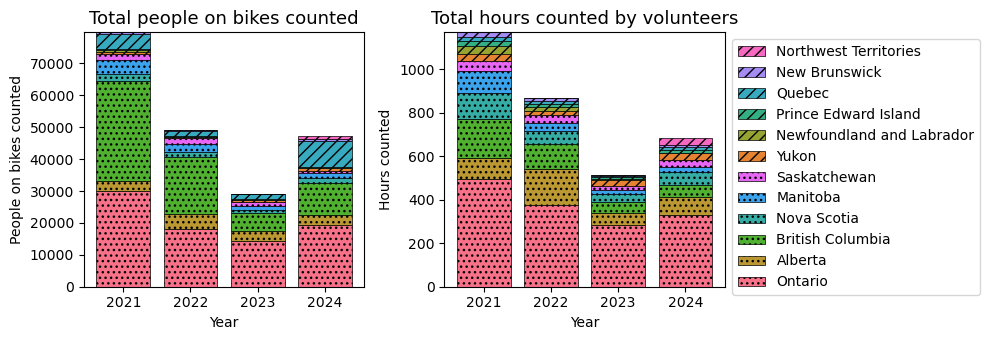

In [40]:
fig, axs = plt.subplots(1,2, figsize = (10,3.5))

#df_plot = on_street_grouped[on_street_grouped['weekday_weekend'] == week].sort_values(by = 'comfort_class')
years = [2021,2022,2023,2024]
bottom = np.zeros(len(years))

#mode_colours = ['green', 'blue', 'gold', 'red']
#mode_labels = ['Bikes', 'Pedestrians', 'Personal vehicles', 'Oversized vehicles']
count = 0
for i, row in summary_table.iterrows():
    vals = row[[ 'bike_total_2021', 'bike_total_2022', 'bike_total_2023', 'bike_total_2024']].values.astype('int')
    bars = axs[0].bar(years, list(vals), bottom = bottom, label = row['geocoded_province'], color = colors[count], edgecolor = 'k', linewidth = 0.5)
    if count > 5:
        for b in bars:
            b.set_hatch('///')
            
    else:
        for b in bars:
            b.set_hatch('...')
    bottom += vals
    count += 1



axs[0].set_xticks(years);


axs[0].set_xlabel("Year")

bottom = np.zeros(len(years))

#mode_colours = ['green', 'blue', 'gold', 'red']
#mode_labels = ['Bikes', 'Pedestrians', 'Personal vehicles', 'Oversized vehicles']
count = 0
for i, row in summary_table.iterrows():
    vals = row[['total_time_hours_2021',
        'total_time_hours_2022',  'total_time_hours_2023',  'total_time_hours_2024']].values.astype('int')
    bars = axs[1].bar(years, list(vals), bottom = bottom, label = row['geocoded_province'], color = colors[count], edgecolor = 'k', linewidth = 0.5)
    if count > 5:
        for b in bars:
            b.set_hatch('///')
            
    else:
        for b in bars:
            b.set_hatch('...')
    bottom += vals
    count += 1

    
handles, labels = axs[1].get_legend_handles_labels()
axs[1].legend(list(reversed(handles)), list(reversed(labels)), loc='upper left', bbox_to_anchor = (1,1), fontsize = 10)
axs[1].set_xticks(years);

axs[1].set_xlabel("Year")

axs[1].set_ylabel("Hours counted")
axs[0].set_ylabel("People on bikes counted")
axs[0].set_title("Total people on bikes counted", fontsize = 13)
axs[1].set_title("Total hours counted by volunteers", fontsize = 13)



plt.tight_layout()
plt.savefig("total_bikes_and_hours.pdf")
plt.savefig("total_bikes_and_hours.png", dpi = 300)

### Format Table 1

In [41]:
summary_table

,geocoded_province,bike_total_2021,bike_total_2022,bike_total_2023,bike_total_2024,total_time_hours_2021,total_time_hours_2022,total_time_hours_2023,total_time_hours_2024
7,Ontario,29975,18220,14225,19197,494,378,285,331
0,Alberta,3258,4617,3115,3247,99,166,53,82
1,British Columbia,31150,17815,5845,10042,178,111,50,56
6,Nova Scotia,2372,1710,867,1672,122,64,41,58
2,Manitoba,4419,2496,1308,1341,102,35,17,26
10,Saskatchewan,1812,1615,1215,644,44,36,17,31
11,Yukon,714,367,675,1097,30,19,26,31
4,Newfoundland and Labrador,368,103,20,1,40,20,6,1
8,Prince Edward Island,296,185,112,229,22,10,11,15
9,Quebec,4794,1601,1664,8333,20,16,4,12


In [42]:
totals = summary_table.sum(axis = 0).values

In [43]:
totals[0] = 'Total'

In [44]:
summary_table.loc[100] = totals

In [45]:
import re
def thous(x, sep=',', dot='.'):
    num, _, frac = str(x).partition(dot)
    num = re.sub(r'(\d{3})(?=\d)', r'\1'+sep, num[::-1])[::-1]
    if frac:
        num += dot + frac
    return num

In [46]:
for col in ['bike_total_2021',        'bike_total_2022',
              'bike_total_2023',        'bike_total_2024']:
    summary_table.loc[:, col] = summary_table[col].apply(lambda x: thous(x, sep = ','))

/tmp/ipykernel_9252/3532559587.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['29,975' '3,258' '31,150' '2,372' '4,419' '1,812' '714' '368' '296'
 '4,794' '577' '0' '79,735']' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  summary_table.loc[:, col] = summary_table[col].apply(lambda x: thous(x, sep = ','))
/tmp/ipykernel_9252/3532559587.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['18,220' '4,617' '17,815' '1,710' '2,496' '1,615' '367' '103' '185'
 '1,601' '493' '53' '49,275']' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  summary_table.loc[:, col] = summary_table[col].apply(lambda x: thous(x, sep = ','))
/tmp/ipykernel_9252/3532559587.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of panda

In [47]:
summary_table.columns

Index(['geocoded_province', 'bike_total_2021', 'bike_total_2022',
       'bike_total_2023', 'bike_total_2024', 'total_time_hours_2021',
       'total_time_hours_2022', 'total_time_hours_2023',
       'total_time_hours_2024'],
      dtype='object')

In [48]:
summary_table

,geocoded_province,bike_total_2021,bike_total_2022,bike_total_2023,bike_total_2024,total_time_hours_2021,total_time_hours_2022,total_time_hours_2023,total_time_hours_2024
7,Ontario,"29,975","18,220","14,225","19,197",494,378,285,331
0,Alberta,"3,258","4,617","3,115","3,247",99,166,53,82
1,British Columbia,"31,150","17,815","5,845","10,042",178,111,50,56
6,Nova Scotia,"2,372","1,710",867,"1,672",122,64,41,58
2,Manitoba,"4,419","2,496","1,308","1,341",102,35,17,26
10,Saskatchewan,"1,812","1,615","1,215",644,44,36,17,31
11,Yukon,714,367,675,"1,097",30,19,26,31
4,Newfoundland and Labrador,368,103,20,1,40,20,6,1
8,Prince Edward Island,296,185,112,229,22,10,11,15
9,Quebec,"4,794","1,601","1,664","8,333",20,16,4,12


In [49]:
summary_table.to_csv("summary_table.csv", index = None, sep = ';')

### Summary stats

In [50]:
# total bikes across all four years
agg_counts['bike_total'].sum()

np.int64(205308)

In [51]:
# Unique communities
len(agg_counts['geocoded_city'].unique())

64

In [52]:
# unique sessions
len(agg_counts)

1860

Sessions assigned to a count slot

In [53]:
agg_counts[agg_counts['count_session_label'] != 'not_assigned'].shape

(1806, 36)

In [54]:
for year in [2021, 2022, 2023, 2024]:
    print(agg_counts[(agg_counts['count_session_label'] != 'not_assigned')
                    & (agg_counts['year'] == year)].shape[0])

654
485
300
367


In [55]:
agg_counts[agg_counts['count_session_label'] != 'not_assigned']['bike_total'].sum()

np.int64(201331)

In [56]:
np.quantile(agg_counts['bikes_per_hour'], 0.9)

np.float64(153.30978260869574)

In [57]:
np.quantile(agg_counts['bikes_per_hour'], 0.95)

np.float64(249.29396697851647)

In [58]:
np.quantile(agg_counts['bikes_per_hour'], 0.99)

np.float64(563.0432432432433)

In [59]:
agg_counts[agg_counts['bikes_per_hour'] > np.quantile(agg_counts['bikes_per_hour'], 
                                                      0.99)].sort_values('bikes_per_hour')[['geocoded_city', 'bike_total', 'bikes_per_hour', 'comfort_class']]

,geocoded_city,bike_total,bikes_per_hour,comfort_class
555,Montreal,1081,564.000000,High
517,Toronto,1280,568.888889,High
553,Montreal,337,577.714286,High
187,Vancouver,1187,598.487395,High
811,Vancouver,1197,603.529412,High
788,Vancouver,1198,609.152542,High
570,Montreal,1235,633.333333,High
1802,Hamilton,71,648.730964,High
932,Toronto,1336,722.162162,High
1579,Vancouver,1477,727.785382,High


## Can-BICS

In [60]:
rcParams['axes.prop_cycle'] = matplotlib.cycler(color=cm.viridis(np.linspace(0,1,4))) 

In [61]:
comfort_mapping = {'Low':0,  'High':2, 'Medium':1}

In [62]:
#using https://chatrlab.ca/wp-content/uploads/2022/09/canbics-graphic-no-title.png?w=1024
# and https://imagecolorpicker.com/
highcolour = '#37a76f'
mediumcolour = '#92d14f'
lowcolour = '#a5a5a5'

In [63]:
agg_counts['comfort_class_int'] = agg_counts['comfort_class'].map(comfort_mapping)

In [64]:
agg_counts['other_cycle_facility'] = agg_counts['other_cycle_facility'].str.strip()

In [65]:
# use the explicity type in "other infrastructre" for clarity
agg_counts['combined_facility'] = agg_counts['other_cycle_facility'].fillna(agg_counts['can_bics_facility'])

In [66]:
agg_counts['combined_facility'].unique()

array([nan, 'Cycle track', 'Local street shared roadway',
       'Not classified', 'Multi-use path', 'Major street shared lane',
       'Painted bike lane', 'Multi-use trail', 'Local street bikeway',
       'Bike path'], dtype=object)

In [67]:
agg_counts[agg_counts['can_bics_facility'] == 'Non-conforming']['other_cycle_facility'].unique()

array(['Local street shared roadway', 'Major street shared lane',
       'Multi-use trail'], dtype=object)

In [68]:
facility_dict_full = {'Painted bike lane':'Painted bike lane', 'Cycle track':'Cycle track',
       'Not classified':'No infrastructure', 'Multi-use path':'Multi-use path', 'Local street bikeway':'Local street bikeway',
       'Bike path': 'Bike path',
        'Local street shared roadway':'Local street shared roadway', 
        'Major street shared lane':'Major street shared lane',
       'Multi-use trail':'Unpaved multi-use trail'}

facility_dict = {'Painted bike lane':'Painted bike lane', 'Cycle track':'Cycle track',
       'Not classified':'No infrastructure', 'Multi-use path':'Multi-use path', 'Local street bikeway':'Local street bikeway',
       'Bike path': 'Bike path',
        'Local street shared roadway':'Other infrastructure', 
        'Major street shared lane':'Other infrastructure',
       'Multi-use trail':'Other infrastructure'}

In [69]:
agg_counts['facility_label_full'] = agg_counts['combined_facility'].map(facility_dict_full)
agg_counts['facility_label'] = agg_counts['combined_facility'].map(facility_dict)

In [70]:
# put no infrastructure last
agg_counts.loc[(agg_counts['other_cycle_facility'].isna())
               & (agg_counts['comfort_class'].isna()), 'comfort_class_int'] = -2

agg_counts.loc[~(agg_counts['other_cycle_facility'].isna())
               & (agg_counts['comfort_class'].isna()), 'comfort_class_int'] = -1

In [71]:
agg_counts_canbics = agg_counts[~agg_counts['can_bics_facility'].isna()] # remove na
#agg_counts_canbics = agg_counts_canbics[agg_counts_canbics['can_bics_facility'] != 'Not classified']

In [72]:
agg_counts_canbics.shape

(1703, 40)

In [73]:
agg_counts_canbics['facility_label'].unique()

array(['Cycle track', 'Other infrastructure', 'No infrastructure',
       'Multi-use path', 'Painted bike lane', 'Local street bikeway',
       'Bike path'], dtype=object)

/tmp/ipykernel_9252/1058799048.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right')


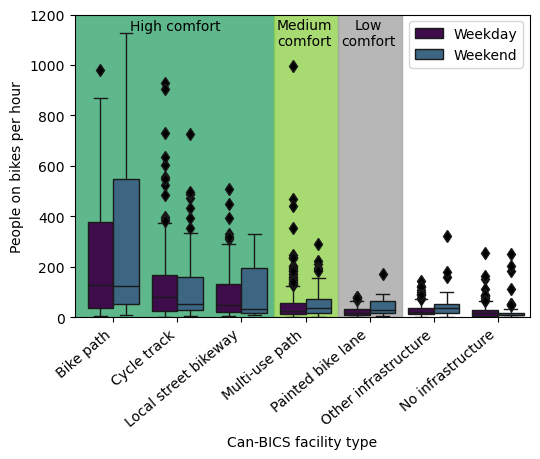

In [74]:
fig, ax = plt.subplots(figsize = (5.5,4.7))

sns.boxplot(data=agg_counts_canbics[
    (agg_counts_canbics['weekday_weekend'] != 'not')].sort_values(by = 'comfort_class_int', 
                                                                                      ascending = False),
            x = 'facility_label', y = 'bikes_per_hour', hue = 'weekday_weekend',
           ax = ax, flierprops={"marker": "d", "mfc": "k"});

ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right')
ax.fill_between([-1,2.5], y1=0,y2=1750, color=highcolour, alpha = 0.8, zorder = 0)
ax.fill_between([2.5,3.5], y1=0,y2=1750, color=mediumcolour, alpha = 0.8, zorder = 0)
ax.fill_between([3.5,4.5], y1=0,y2=1750, color=lowcolour, alpha = 0.8, zorder = 0)
ax.set_xlabel("Can-BICS facility type")
ax.set_xlim(-0.6, 6.5)
ax.set_ylim(0,1200)
ax.set_ylabel("People on bikes per hour")

h, l = ax.get_legend_handles_labels()
legend_labels = []
for lab in l:
    legend_labels.append(lab.capitalize())

loc = 'upper right'
pos = (1,1)
ax.legend(h, legend_labels, title = "", loc = 'upper right', bbox_to_anchor = (1, 1))

ax.annotate("High comfort", xy=(0.22, 0.95), xycoords = 'axes fraction', ha = 'center')
ax.annotate("Medium\ncomfort", xy=(0.505, 0.9), xycoords = 'axes fraction', ha = 'center')
ax.annotate("Low\ncomfort", xy=(0.645, 0.9), xycoords = 'axes fraction', ha = 'center')

plt.tight_layout()
plt.savefig("canbics_all.pdf")
plt.savefig("canbics_all.png", dpi = 300)

### Can-BICS Summary table

In [75]:
agg_counts_canbics['combined_comfort_class'] = agg_counts_canbics['comfort_class'].fillna(agg_counts_canbics['can_bics_facility'])

/tmp/ipykernel_9252/1127599599.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  agg_counts_canbics['combined_comfort_class'] = agg_counts_canbics['comfort_class'].fillna(agg_counts_canbics['can_bics_facility'])


In [76]:
agg_counts_canbics['combined_comfort_class'].unique()

array(['High', 'Non-conforming', 'Not classified', 'Medium', 'Low'],
      dtype=object)

In [77]:
canbics_provinces = agg_counts_canbics.groupby(["geocoded_province", "year", "combined_comfort_class"])["bike_total"].count().reset_index()

In [78]:
canbics_provinces

,geocoded_province,year,combined_comfort_class,bike_total
0,Alberta,2021,High,1
1,Alberta,2021,Low,3
2,Alberta,2021,Medium,21
3,Alberta,2021,Not classified,9
4,Alberta,2022,High,27
...,...,...,...,...
145,Yukon,2023,Non-conforming,1
146,Yukon,2023,Not classified,1
147,Yukon,2024,High,2
148,Yukon,2024,Medium,10


In [79]:
# total counts by province and year
counts_by_province = pd.pivot_table(agg_counts_canbics.groupby(["geocoded_province", "year"])['bike_total'].count().reset_index()[['geocoded_province',
        'year', 'bike_total']],
               values = ['bike_total'], index = ['geocoded_province'],
               columns = ['year']).reset_index()

In [80]:
canbics_provinces_pivot = pd.pivot_table(canbics_provinces[['geocoded_province',
       'combined_comfort_class', 'year', 'bike_total']],
               values = ['bike_total'], index = ['geocoded_province'],
               columns = ['year', 'combined_comfort_class']).reset_index()

In [81]:
canbics_provinces_pivot = canbics_provinces_pivot.fillna(0)

In [82]:
canbics_provinces_pivot['bike_total'] = canbics_provinces_pivot['bike_total'].astype('int')

In [83]:
canbics_provinces_pivot.columns.get_level_values(0)

Index(['geocoded_province', 'bike_total', 'bike_total', 'bike_total',
       'bike_total', 'bike_total', 'bike_total', 'bike_total', 'bike_total',
       'bike_total', 'bike_total', 'bike_total', 'bike_total', 'bike_total',
       'bike_total', 'bike_total', 'bike_total', 'bike_total', 'bike_total',
       'bike_total', 'bike_total'],
      dtype='object')

In [84]:
canbics_provinces_pivot

geocoded_province bike_total             \
year                                                    2021              
combined_comfort_class                                  High Low Medium   
0                                         Alberta          1   3     21   
1                                British Columbia         50   2     20   
2                                        Manitoba          5   0      9   
3                                   New Brunswick          0   0      3   
4                       Newfoundland and Labrador          0   0      0   
5                           Northwest Territories          0   0      0   
6                                     Nova Scotia          4  11     16   
7                                         Ontario         43  13    100   
8                            Prince Edward Island          2   0      0   
9                                          Quebec          8   0      0   
10                                   Saskatchewan          4   1     18   
11                                          Yukon          4   0      7   

                                                                      \
year                                                 2022              
combined_comfort_class Non-conforming Not classified High Low Medium   
0                                   0              9   27   4     53   
1                                   1              4   30   2     13   
2                                  13             22    8   0      6   
3                                   1              4    0   0      5   
4                                   6             18    0   0      0   
5                                   0              0    0   0      0   
6                                   5             16    9   9      8   
7                                  33             32   51  22     97   
8                                   4              7    3   0      0   
9                                   0              0    2   4      0   
10                                  0              1    2   0     19   
11                                  4              3    0   0      5   

                                       ...                                 \
year                                   ... 2023                             
combined_comfort_class Non-conforming  ... High Low Medium Non-conforming   
0                                   2  ...   12   3     19              0   
1                                   1  ...   15   1      9              3   
2                                   2  ...    4   0      2              2   
3                                   0  ...    0   0      1              0   
4                                   1  ...    0   0      0              1   
5                                   0  ...    0   0      0              0   
6                                   2  ...   10   3      4              0   
7                                  12  ...   34  14     72             13   
8                                   2  ...    1   0      0              4   
9                                   0  ...    2   0      0              0   
10                                  0  ...    0   0     13              0   
11                                  4  ...    3   0     11              1   

                                                                      \
year                                  2024                             
combined_comfort_class Not classified High Low Medium Non-conforming   
0                                   3   16   3     18              5   
1                                   3   22   0      6              0   
2                                   3    7   0      4              1   
3                                   1    0   0      4              0   
4                                   4    0   0      0              0   
5                                   0    0   0      3              0   
6                    

In [85]:
canbics_provinces_pivot.columns = canbics_provinces_pivot.columns.get_level_values(0)
canbics_provinces_pivot.columns = ['geocoded_province', 
                            'high_comfort_2021', 'low_comfort_2021', 'medium_comfort_2021', 'non_conforming_2021', 'no_infrastructure_2021',
                            'high_comfort_2022', 'low_comfort_2022', 'medium_comfort_2022', 'non_conforming_2022', 'no_infrastructure_2022',
                            'high_comfort_2023', 'low_comfort_2023', 'medium_comfort_2023', 'non_conforming_2023', 'no_infrastructure_2023',
                            'high_comfort_2024', 'low_comfort_2024', 'medium_comfort_2024', 'non_conforming_2024', 'no_infrastructure_2024']
                                 

In [86]:
counts_by_province = counts_by_province.fillna(0)

In [87]:
counts_by_province.columns = ['geocoded_province', 2021, 2022, 2023, 2024]

In [88]:
# merge with count session totals
canbics_provinces_pivot = canbics_provinces_pivot.merge(counts_by_province, how = 'left', on = 'geocoded_province')

In [89]:
canbics_provinces_pivot

,geocoded_province,high_comfort_2021,low_comfort_2021,medium_comfort_2021,non_conforming_2021,no_infrastructure_2021,high_comfort_2022,low_comfort_2022,medium_comfort_2022,non_conforming_2022,...,no_infrastructure_2023,high_comfort_2024,low_comfort_2024,medium_comfort_2024,non_conforming_2024,no_infrastructure_2024,2021,2022,2023,2024
0,Alberta,1,3,21,0,9,27,4,53,2,...,3,16,3,18,5,2,34.0,99.0,37.0,44.0
1,British Columbia,50,2,20,1,4,30,2,13,1,...,3,22,0,6,0,2,77.0,62.0,31.0,30.0
2,Manitoba,5,0,9,13,22,8,0,6,2,...,3,7,0,4,1,2,49.0,21.0,11.0,14.0
3,New Brunswick,0,0,3,1,4,0,0,5,0,...,1,0,0,4,0,2,8.0,7.0,2.0,6.0
4,Newfoundland and Labrador,0,0,0,6,18,0,0,0,1,...,4,0,0,0,0,1,24.0,13.0,5.0,1.0
5,Northwest Territories,0,0,0,0,0,0,0,0,0,...,0,0,0,3,0,14,0.0,1.0,0.0,17.0
6,Nova Scotia,4,11,16,5,16,9,9,8,2,...,7,16,3,6,1,9,52.0,38.0,24.0,35.0
7,Ontario,43,13,100,33,32,51,22,97,12,...,28,52,18,74,13,20,221.0,210.0,161.0,177.0
8,Prince Edward Island,2,0,0,4,7,3,0,0,2,...,1,2,0,0,6,0,13.0,6.0,6.0,8.0
9,Quebec,8,0,0,0,0,2,4,0,0,...,0,6,0,0,0,0,8.0,6.0,2.0,6.0


In [90]:
canbics_provinces_pivot.columns

Index([     'geocoded_province',      'high_comfort_2021',
             'low_comfort_2021',    'medium_comfort_2021',
          'non_conforming_2021', 'no_infrastructure_2021',
            'high_comfort_2022',       'low_comfort_2022',
          'medium_comfort_2022',    'non_conforming_2022',
       'no_infrastructure_2022',      'high_comfort_2023',
             'low_comfort_2023',    'medium_comfort_2023',
          'non_conforming_2023', 'no_infrastructure_2023',
            'high_comfort_2024',       'low_comfort_2024',
          'medium_comfort_2024',    'non_conforming_2024',
       'no_infrastructure_2024',                     2021,
                           2022,                     2023,
                           2024],
      dtype='object')

In [91]:
## rearrange column order

canbics_summary = canbics_provinces_pivot[['geocoded_province', 
                                'high_comfort_2021', 'high_comfort_2022', 'high_comfort_2023', 'high_comfort_2024',
                     'medium_comfort_2021', 'medium_comfort_2022', 'medium_comfort_2023', 'medium_comfort_2024', 
                       'low_comfort_2021', 'low_comfort_2022', 'low_comfort_2023',  'low_comfort_2024',
                      'non_conforming_2021','non_conforming_2022','non_conforming_2023','non_conforming_2024',     
                    'no_infrastructure_2021','no_infrastructure_2022','no_infrastructure_2023','no_infrastructure_2024',
                                   2021,  2022,  2023,  2024]]

# alternate order with years grouped together

canbics_summary = canbics_provinces_pivot[[  'geocoded_province',      'high_comfort_2021',
               'medium_comfort_2021', 'low_comfort_2021',  
          'non_conforming_2021', 'no_infrastructure_2021', 2021,
            'high_comfort_2022',    'medium_comfort_2022',      'low_comfort_2022',
           'non_conforming_2022',
       'no_infrastructure_2022',   2022,   'high_comfort_2023',
                'medium_comfort_2023',  'low_comfort_2023',
          'non_conforming_2023', 'no_infrastructure_2023', 2023,
            'high_comfort_2024',   'medium_comfort_2024',      'low_comfort_2024',
             'non_conforming_2024',
       'no_infrastructure_2024', 2024]]

In [92]:
for year in [2021,2022,2023,2024]:
    canbics_summary[year] = canbics_summary[year].astype('int')

In [93]:
# confirm that the totals match up - removing sites with no can-bics classification
for year in [2021, 2022, 2023, 2024]:

    assert np.all(canbics_summary[['high_comfort_%s' %year,
               'medium_comfort_%s' %year, 'low_comfort_%s' %year,  
          'non_conforming_%s' %year, 'no_infrastructure_%s' %year]].sum(axis = 1) == canbics_summary[year])

In [94]:
canbics_summary

,geocoded_province,high_comfort_2021,medium_comfort_2021,low_comfort_2021,non_conforming_2021,no_infrastructure_2021,2021,high_comfort_2022,medium_comfort_2022,low_comfort_2022,...,low_comfort_2023,non_conforming_2023,no_infrastructure_2023,2023,high_comfort_2024,medium_comfort_2024,low_comfort_2024,non_conforming_2024,no_infrastructure_2024,2024
0,Alberta,1,21,3,0,9,34,27,53,4,...,3,0,3,37,16,18,3,5,2,44
1,British Columbia,50,20,2,1,4,77,30,13,2,...,1,3,3,31,22,6,0,0,2,30
2,Manitoba,5,9,0,13,22,49,8,6,0,...,0,2,3,11,7,4,0,1,2,14
3,New Brunswick,0,3,0,1,4,8,0,5,0,...,0,0,1,2,0,4,0,0,2,6
4,Newfoundland and Labrador,0,0,0,6,18,24,0,0,0,...,0,1,4,5,0,0,0,0,1,1
5,Northwest Territories,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,3,0,0,14,17
6,Nova Scotia,4,16,11,5,16,52,9,8,9,...,3,0,7,24,16,6,3,1,9,35
7,Ontario,43,100,13,33,32,221,51,97,22,...,14,13,28,161,52,74,18,13,20,177
8,Prince Edward Island,2,0,0,4,7,13,3,0,0,...,0,4,1,6,2,0,0,6,0,8
9,Quebec,8,0,0,0,0,8,2,0,4,...,0,0,0,2,6,0,0,0,0,6


In [95]:
# rearrange to match province order in table 1
canbics_summary = canbics_summary.reindex([7,0,1,6,2,10,11,4,8,9,3,5])

In [96]:
canbics_summary.to_csv("summary_table_canbics.csv", index = None, sep = ";")

In [97]:
# save as separate years

for year in [2021, 2022, 2023, 2024]:

    canbics_summary[['geocoded_province', 'high_comfort_%s' %year,
               'medium_comfort_%s' %year, 'low_comfort_%s' %year,  
          'non_conforming_%s' %year, 'no_infrastructure_%s' %year, year]].to_csv("summary_table_canbics_%s.csv" %year, index = None, sep = ";")

In [98]:
for year in [2021, 2022, 2023, 2024]:
    canbics_provinces_pivot['high_comfort_frac_%s' %year] = canbics_provinces_pivot['high_comfort_%s' %year] / canbics_provinces_pivot[year]
    canbics_provinces_pivot['medium_comfort_frac_%s' %year] = canbics_provinces_pivot['medium_comfort_%s' %year] / canbics_provinces_pivot[year]
    canbics_provinces_pivot['low_comfort_frac_%s' %year] = canbics_provinces_pivot['low_comfort_%s' %year] / canbics_provinces_pivot[year]

This is the fraction of sites in each comfort class, but I'm not sure it's that useful given the large fluctuations in site numbers.

What we want to communicate is that there were few to no changes to infrastructure in multi-year sites. Is there a way to show that visually?

In [99]:
canbics_provinces_pivot[['geocoded_province', 'high_comfort_frac_2021',
         'high_comfort_frac_2022',   'high_comfort_frac_2023',
         'high_comfort_frac_2024', 'medium_comfort_frac_2021',
          'low_comfort_frac_2021', 'medium_comfort_frac_2022',
          'low_comfort_frac_2022', 'medium_comfort_frac_2023',
          'low_comfort_frac_2023', 'medium_comfort_frac_2024',
          'low_comfort_frac_2024']]

,geocoded_province,high_comfort_frac_2021,high_comfort_frac_2022,high_comfort_frac_2023,high_comfort_frac_2024,medium_comfort_frac_2021,low_comfort_frac_2021,medium_comfort_frac_2022,low_comfort_frac_2022,medium_comfort_frac_2023,low_comfort_frac_2023,medium_comfort_frac_2024,low_comfort_frac_2024
0,Alberta,0.029412,0.272727,0.324324,0.363636,0.617647,0.088235,0.535354,0.040404,0.513514,0.081081,0.409091,0.068182
1,British Columbia,0.649351,0.483871,0.483871,0.733333,0.259740,0.025974,0.209677,0.032258,0.290323,0.032258,0.200000,0.000000
2,Manitoba,0.102041,0.380952,0.363636,0.500000,0.183673,0.000000,0.285714,0.000000,0.181818,0.000000,0.285714,0.000000
3,New Brunswick,0.000000,0.000000,0.000000,0.000000,0.375000,0.000000,0.714286,0.000000,0.500000,0.000000,0.666667,0.000000
4,Newfoundland and Labrador,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,Northwest Territories,NaN,0.000000,NaN,0.000000,NaN,NaN,0.000000,0.000000,NaN,NaN,0.176471,0.000000
6,Nova Scotia,0.076923,0.236842,0.416667,0.457143,0.307692,0.211538,0.210526,0.236842,0.166667,0.125000,0.171429,0.085714
7,Ontario,0.194570,0.242857,0.211180,0.293785,0.452489,0.058824,0.461905,0.104762,0.447205,0.086957,0.418079,0.101695
8,Prince Edward Island,0.153846,0.500000,0.166667,0.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,Quebec,1.000000,0.333333,1.000000,1.000000,0.000000,0.000000,0.000000,0.666667,0.000000,0.000000,0.000000,0.000000


### Group high/med/low comfort and do Anova

### Can-BICS stats for each year

- Test high / med / low
- Test high / med / low for weekday and weekend separately
- Test all years combined

In [100]:
from scipy.stats import f_oneway

#### All data

In [101]:
data = agg_counts_canbics[
    (agg_counts_canbics['weekday_weekend'] != 'not')].sort_values(by = 'comfort_class_int', ascending = False)

In [102]:
data[~data['comfort_class_int'].isna()].shape

(1666, 41)

In [103]:
334+370+229+285

1218

In [104]:
data.shape

(1666, 41)

In [105]:
data['can_bics_facility'].unique()

array(['Bike path', 'Cycle track', 'Local street bikeway',
       'Multi-use path', 'Painted bike lane', 'Non-conforming',
       'Not classified'], dtype=object)

In [106]:
# Anova with all groups
f = f_oneway(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Medium']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Low']['bikes_per_hour'],
            data[data['can_bics_facility'] == 'Non-conforming']['bikes_per_hour'],
            data[data['can_bics_facility'] == 'Not classified']['bikes_per_hour'])

In [107]:
print("statistic: ", round(f.statistic, 1))
print("p-value: ", round(f.pvalue, np.int64(np.abs(np.floor(np.log10(f.pvalue))))))

statistic:  84.1
p-value:  3.999999999999999e-65


Since the standard deviations are not equal between the groups, possible we violate ANOVA assumptions.

In [108]:
from scipy.stats import kruskal

In [109]:
kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Medium']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Low']['bikes_per_hour'],
            data[data['can_bics_facility'] == 'Non-conforming']['bikes_per_hour'],
            data[data['can_bics_facility'] == 'Not classified']['bikes_per_hour'])

print("statistic: ", round(kw.statistic, 1))
print("p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))

statistic:  307.0
p-value:  2.999999999999999e-65


#### Each year separately

In [110]:
for i, year in enumerate([2021,2022,2023,2024]):
    data = agg_counts_canbics[
        (agg_counts_canbics['weekday_weekend'] != 'not')
       & (agg_counts['year'] == year)].sort_values(by = 'comfort_class_int', ascending = False)
    f =  f_oneway(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Medium']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Low']['bikes_per_hour'])
    
    print(data[~data['comfort_class_int'].isna()].shape)
    print(year, "F-statistic: ", round(f.statistic, 1), "p-value: ", round(f.pvalue, np.int64(np.abs(np.floor(np.log10(f.pvalue))))))
    
    kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Medium']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Low']['bikes_per_hour'])
    
    print(year, "H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))

(514, 41)
2021 F-statistic:  53.1 p-value:  1e-20
2021 H-statistic:  64.1 p-value:  1e-14
(485, 41)
2022 F-statistic:  31.5 p-value:  2e-13
2022 H-statistic:  47.2 p-value:  6e-11
(300, 41)
2023 F-statistic:  6.3 p-value:  0.002
2023 H-statistic:  22.9 p-value:  1e-05
(367, 41)
2024 F-statistic:  17.0 p-value:  1e-07
2024 H-statistic:  39.9 p-value:  2e-09


/tmp/ipykernel_9252/176109655.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = agg_counts_canbics[
/tmp/ipykernel_9252/176109655.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = agg_counts_canbics[
/tmp/ipykernel_9252/176109655.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = agg_counts_canbics[
/tmp/ipykernel_9252/176109655.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = agg_counts_canbics[


More checks - Anova same as t-test with two samples

ANOVA (same as t test for two samples)

In [111]:
f_oneway(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Low']['bikes_per_hour'])

F_onewayResult(statistic=np.float64(7.428203276425119), pvalue=np.float64(0.007223503592072008))

In [112]:
from scipy.stats import ttest_ind

In [113]:
ttest_ind(data[data['comfort_class'] == 'High']['bikes_per_hour'], data[data['comfort_class'] == 'Low']['bikes_per_hour'])

TtestResult(statistic=np.float64(2.725473037185494), pvalue=np.float64(0.007223503592071934), df=np.float64(143.0))

In [114]:
kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Medium']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Low']['bikes_per_hour'])

KruskalResult(statistic=np.float64(39.92535759662898), pvalue=np.float64(2.139531839756419e-09))

### High-medium and high-low comparisons

In [115]:
for i, year in enumerate([2021,2022,2023,2024]):
    data = agg_counts_canbics[
        (agg_counts_canbics['weekday_weekend'] != 'not')
       & (agg_counts['year'] == year)].sort_values(by = 'comfort_class_int', ascending = False)
    
    kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Medium']['bikes_per_hour'])
    
    print(year, "high-med H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))
    
    kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Low']['bikes_per_hour'])
    
    print(year, "high-low H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))
    
    kw = kruskal(data[data['comfort_class'] == 'Medium']['bikes_per_hour'], 
         data[data['comfort_class'] == 'Low']['bikes_per_hour'])
    
    print(year, "med-low H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))
    
    kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['can_bics_facility'] == 'Non-conforming']['bikes_per_hour'])
    
    print(year, "High-non-conforming H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))
    
    kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
         data[data['can_bics_facility'] == 'Not classified']['bikes_per_hour'])
    
    print(year, "High-not classified H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))

2021 high-med H-statistic:  54.2 p-value:  2e-13
2021 high-low H-statistic:  28.0 p-value:  1e-07
2021 med-low H-statistic:  4.3 p-value:  0.04
2021 High-non-conforming H-statistic:  43.1 p-value:  5e-11
2021 High-not classified H-statistic:  101.9 p-value:  6e-24
2022 high-med H-statistic:  40.4 p-value:  2e-10
2022 high-low H-statistic:  22.3 p-value:  2e-06
2022 med-low H-statistic:  1.2 p-value:  0.3
2022 High-non-conforming H-statistic:  10.1 p-value:  0.001
2022 High-not classified H-statistic:  61.7 p-value:  4e-15
2023 high-med H-statistic:  16.7 p-value:  4e-05
2023 high-low H-statistic:  13.6 p-value:  0.0002
2023 med-low H-statistic:  2.5 p-value:  0.1
2023 High-non-conforming H-statistic:  13.1 p-value:  0.0003
2023 High-not classified H-statistic:  34.4 p-value:  5e-09
2024 high-med H-statistic:  26.3 p-value:  3e-07
2024 high-low H-statistic:  22.5 p-value:  2e-06
2024 med-low H-statistic:  7.9 p-value:  0.005
2024 High-non-conforming H-statistic:  15.4 p-value:  8e-05
20

/tmp/ipykernel_9252/565802369.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = agg_counts_canbics[
/tmp/ipykernel_9252/565802369.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = agg_counts_canbics[
/tmp/ipykernel_9252/565802369.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = agg_counts_canbics[
/tmp/ipykernel_9252/565802369.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = agg_counts_canbics[


In [116]:
# all years

data = agg_counts_canbics[
    (agg_counts_canbics['weekday_weekend'] != 'not')].sort_values(by = 'comfort_class_int', ascending = False)

kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
     data[data['comfort_class'] == 'Medium']['bikes_per_hour'])

print("high-med H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))

kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
     data[data['comfort_class'] == 'Low']['bikes_per_hour'])

print("high-low H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))

kw = kruskal(data[data['comfort_class'] == 'Medium']['bikes_per_hour'], 
     data[data['comfort_class'] == 'Low']['bikes_per_hour'])

print( "med-low H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))

kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
     data[data['can_bics_facility'] == 'Non-conforming']['bikes_per_hour'])

print(year, "High-non-conforming H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))

kw = kruskal(data[data['comfort_class'] == 'High']['bikes_per_hour'], 
     data[data['can_bics_facility'] == 'Not classified']['bikes_per_hour'])

print(year, "High-not classified H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))

high-med H-statistic:  130.3 p-value:  4e-30
high-low H-statistic:  85.0 p-value:  3e-20
med-low H-statistic:  12.9 p-value:  0.0003
2024 High-non-conforming H-statistic:  72.3 p-value:  2e-17
2024 High-not classified H-statistic:  232.4 p-value:  2e-52


## Multi-year sites plot with error bars

- test year vs. year comparisons for statistical difference

In [117]:
# get average across all communities for all-year repeated sites only
to_melt = agg_counts_pivot_allyears.drop(columns = ['bike_total'])

to_melt.columns = list(to_melt.columns.get_level_values(0)[:-4]) + list(to_melt.columns.get_level_values(1)[-4:])

agg_counts_all_years = to_melt.melt(id_vars=['grouped_counterpoint_id', 'geocoded_city', 'geocoded_province', 
                                                                'count_session_label', 'weekday_weekend'])

agg_counts_all_years = agg_counts_all_years.rename(columns = {"value": "bikes_per_hour", "variable": "year"})

/tmp/ipykernel_9252/1684360840.py:2: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  to_melt = agg_counts_pivot_allyears.drop(columns = ['bike_total'])


In [118]:
agg_counts_all_years.shape

(148, 7)

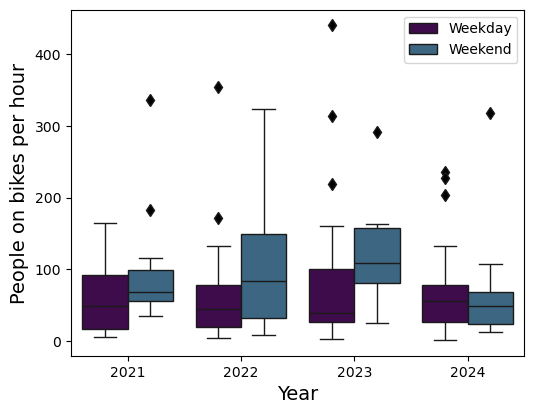

In [119]:
fig, ax = plt.subplots(figsize = (6,4.5), facecolor = 'white')

colors = cm.viridis(np.linspace(0,1,8))

width = 0.4
data = agg_counts_all_years

weekday = data[(data['weekday_weekend'] == 'weekday')]
weekend = data[(data['weekday_weekend'] == 'weekend')]

bars = sns.boxplot(data=data,
           x = 'year', y = 'bikes_per_hour', hue = 'weekday_weekend',
           ax = ax, flierprops={"marker": "d", "mfc": "k"});



#ax.set_xticks(np.array([2021,2022,2023,2024]) + width / 2)
#ax.set_xticklabels(['2021', '2022', '2023', '2024'], fontsize = header_fontsize, color = 'white')
#x.set_xticks([2021, 2022, 2023])

ax.set_ylabel("People on bikes per hour", fontsize = 14, color = 'k')

ylims = ax.get_ylim()
ax.set_ylim(ylims[0], ylims[1]*1) # so legend doesn't cut it off

#ax.yaxis.label.set_color('white')
#ax.tick_params(axis='y', colors='white')

#ax.xaxis.label.set_color('white')
#ax.tick_params(axis='x', colors='white')
ax.set_xlabel("Year", fontsize = 14, color = 'k')

h, l = ax.get_legend_handles_labels()
legend_labels = []
for lab in l:
    legend_labels.append(lab.capitalize())

loc = 'upper right'
pos = (1,1)
ax.legend(h, legend_labels, title = "", loc = loc, bbox_to_anchor = pos)
    

plt.tight_layout(pad = 2, rect = (0, 0, 0.95, 1))

plt.savefig("repeated_sites_avg_boxplot.png", dpi = 300)
plt.savefig("repeated_sites_avg_boxplot.pdf")

### Stats for bikes per hour between years

In [120]:
# all years

data = agg_counts_all_years

kw = kruskal(data[data['year'] == 2021]['bikes_per_hour'], 
             data[data['year'] == 2022]['bikes_per_hour'],
             data[data['year'] == 2023]['bikes_per_hour'],
            data[data['year'] == 2024]['bikes_per_hour'])

print("4-years H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, np.int64(np.abs(np.floor(np.log10(kw.pvalue))))))


4-years H-statistic:  1.4 p-value:  0.7


In [121]:
f =  f_oneway(data[data['year'] == 2021]['bikes_per_hour'], 
         data[data['year'] == 2022]['bikes_per_hour'],
         data[data['year'] == 2023]['bikes_per_hour'],
        data[data['year'] == 2024]['bikes_per_hour'])

print(year, "F-statistic: ", round(f.statistic, 1), "p-value: ", round(f.pvalue, np.int64(np.abs(np.floor(np.log10(f.pvalue))))))

2024 F-statistic:  0.8 p-value:  0.5


In [122]:
for year1 in years:
    for year2 in years:
        if year1 == year2:
            continue
        if year2 < year1:
            continue
        f =  f_oneway(data[data['year'] == year1]['bikes_per_hour'], 
         data[data['year'] == year2]['bikes_per_hour'])
        
        print(year1, year2, "F-statistic: ", round(f.statistic, 1), "p-value: ", round(f.pvalue, 2))

2021 2022 F-statistic:  0.4 p-value:  0.53
2021 2023 F-statistic:  1.8 p-value:  0.18
2021 2024 F-statistic:  0.0 p-value:  0.95
2022 2023 F-statistic:  0.4 p-value:  0.51
2022 2024 F-statistic:  0.3 p-value:  0.58
2023 2024 F-statistic:  1.6 p-value:  0.21


In [123]:
kw = kruskal(data[data['year'] == 2021]['bikes_per_hour'], 
             data[data['year'] == 2022]['bikes_per_hour'],
             data[data['year'] == 2023]['bikes_per_hour'],
            data[data['year'] == 2024]['bikes_per_hour'])

print("4-years H-statistic: ", round(kw.statistic, 1), "p-value: ", round(kw.pvalue, 2))

4-years H-statistic:  1.4 p-value:  0.71


Split by weekday  / weekend:

In [124]:
# weekday only
for year1 in years:
    for year2 in years:
        if year1 == year2:
            continue
        if year2 < year1:
            continue
        f =  f_oneway(data[(data['year'] == year1) & (data['weekday_weekend'] == 'weekday')]['bikes_per_hour'], 
         data[(data['year'] == year2) & (data['weekday_weekend'] == 'weekday')]['bikes_per_hour'])
        
        print(year1, year2, "F-statistic: ", round(f.statistic, 1), "p-value: ", 
              round(f.pvalue, 2))

2021 2022 F-statistic:  0.2 p-value:  0.67
2021 2023 F-statistic:  1.5 p-value:  0.23
2021 2024 F-statistic:  0.8 p-value:  0.37
2022 2023 F-statistic:  0.6 p-value:  0.43
2022 2024 F-statistic:  0.1 p-value:  0.73
2023 2024 F-statistic:  0.3 p-value:  0.59


In [125]:
# weekday only
for year1 in years:
    for year2 in years:
        if year1 == year2:
            continue
        if year2 < year1:
            continue
        f =  f_oneway(data[(data['year'] == year1) & (data['weekday_weekend'] == 'weekend')]['bikes_per_hour'], 
         data[(data['year'] == year2) & (data['weekday_weekend'] == 'weekend')]['bikes_per_hour'])
        
        print(year1, year2, "F-statistic: ", round(f.statistic, 1), "p-value: ", 
              round(f.pvalue, 2))

2021 2022 F-statistic:  0.2 p-value:  0.64
2021 2023 F-statistic:  0.4 p-value:  0.54
2021 2024 F-statistic:  0.6 p-value:  0.43
2022 2023 F-statistic:  0.0 p-value:  0.99
2022 2024 F-statistic:  1.4 p-value:  0.26
2023 2024 F-statistic:  2.2 p-value:  0.15


### Spatial Access Measures

Link to data here: https://www150.statcan.gc.ca/n1/pub/27-26-0001/272600012023001-eng.htm

In [126]:
counterpoint_to_dbuid = pd.read_csv("data/counterpoint_to_dbuid.csv")

In [127]:
# spatial access measures

sam_data = pd.read_csv("data/sam-msa-eng/acs_cycling.csv",
                      encoding='latin-1')

sam_walk = pd.read_csv("data/sam-msa-eng/acs_walking.csv",
                      encoding='latin-1')

sam_transit = pd.read_csv("data/sam-msa-eng/acs_public_transit_peak.csv",
                      encoding='latin-1')


In [128]:
agg_counts = agg_counts.merge(counterpoint_to_dbuid, on = 'grouped_counterpoint_id', how = 'left')

In [129]:
agg_counts = agg_counts.merge(sam_data[['DBUID', 'acs_idx_emp']], on = 'DBUID', how = 'left')

In [130]:
agg_counts = agg_counts.merge(sam_walk[['DBUID', 'acs_idx_emp']], on = 'DBUID', how = 'left', suffixes = ('_bike', '_walk'))

In [131]:
agg_counts = agg_counts.merge(sam_transit[['DBUID', 'acs_idx_emp']], on = 'DBUID', how = 'left')

In [132]:
import statsmodels.formula.api as smf

In [133]:
lm1 = smf.ols(formula='bikes_per_hour ~ acs_idx_emp_bike', 
             data=agg_counts).fit()

In [134]:
lm1.rsquared

np.float64(0.309890068159855)

In [135]:
lm1.params

Intercept            10.325853
acs_idx_emp_bike    341.030596
dtype: float64

In [136]:
lm1b = smf.ols(formula='bikes_per_hour ~ acs_idx_emp_walk', 
             data=agg_counts).fit()

In [137]:
lm1b.rsquared

np.float64(0.1399190324766445)

In [138]:
# transit
lm1c = smf.ols(formula='bikes_per_hour ~ acs_idx_emp', 
             data=agg_counts).fit()

In [139]:
lm1c.rsquared

np.float64(0.19563295531100822)

Correlation is much stronger for biking accessibility than walking or transit accessibility

In [140]:
sam_data.columns

Index(['DBUID', 'CSDUID', 'CSDNAME', 'CMAUID', 'CMANAME', 'PRUID', 'PRCODE',
       'acs_idx_hf', 'acs_idx_emp', 'acs_idx_srf', 'acs_idx_psef',
       'acs_idx_ef', 'acs_idx_caf', 'acs_lvl_gs-1', 'acs_lvl_gs-3',
       'acs_lvl_gs-5'],
      dtype='object')

In [141]:
test_bike_acc = agg_counts.merge(sam_data[['DBUID', 'acs_idx_hf', 'acs_idx_srf', 'acs_idx_psef', 'acs_idx_ef', 'acs_idx_caf']], on = 'DBUID', how = 'left')

Testing all the other accessibility values: the strongest correlation is with accessibility to employment (followed closely by healthcare). 

In [142]:
for col in ['acs_idx_emp_bike','acs_idx_hf', 'acs_idx_srf', 'acs_idx_psef', 'acs_idx_ef', 'acs_idx_caf']:
    lm = smf.ols(formula='bikes_per_hour ~ {}'.format(col), 
             data=test_bike_acc).fit()
    print(lm.rsquared)
    print(lm.params)
    print(" ")

0.309890068159855
Intercept            10.325853
acs_idx_emp_bike    341.030596
dtype: float64
 
0.2754034628977091
Intercept      13.940427
acs_idx_hf    358.744801
dtype: float64
 
0.20566701003757248
Intercept       12.404116
acs_idx_srf    307.344643
dtype: float64
 
0.17342305906395106
Intercept        39.565293
acs_idx_psef    498.587160
dtype: float64
 
0.08390262169236296
Intercept      26.480694
acs_idx_ef    198.469178
dtype: float64
 
0.21588797041673158
Intercept       28.091426
acs_idx_caf    287.350636
dtype: float64
 


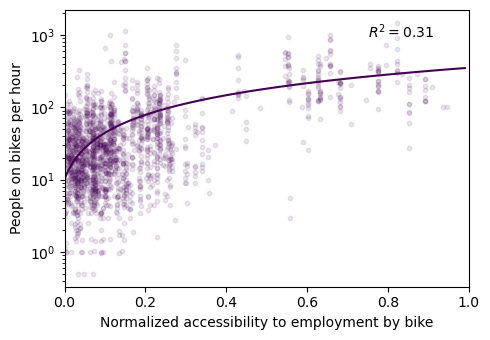

In [143]:
fig, ax = plt.subplots(figsize = (5,3.5))

# SAM
ax.scatter(agg_counts['acs_idx_emp_bike'], agg_counts['bikes_per_hour'], alpha = 0.1, s = 10)

xvals = np.arange(0,1,0.01)
yvals = xvals*lm1.params.acs_idx_emp_bike + lm1.params.Intercept
ax.plot(xvals, yvals)

ax.set_yscale('log')

ax.annotate("$R^2 = {}$".format(round(lm1.rsquared,2)), xy = (0.75,0.9), xycoords='axes fraction')

ax.set_ylabel("People on bikes per hour")
ax.set_xlabel("Normalized accessibility to employment by bike")

ax.set_xlim(0,1)

plt.tight_layout()

plt.savefig("bikes_per_hour_vs_SAM.png", dpi = 300)
plt.savefig("bikes_per_hour_vs_SAM.pdf")

### Compare population sizes (for discussion)

In [144]:
cma_pop = pd.read_csv("data/cma_population_2021.csv")

In [145]:
city_counts = agg_counts['geocoded_city'].value_counts().reset_index()

In [146]:
city_counts.columns = ['geocoded_city', 'num_counts']

In [147]:
city_counts_pop = city_counts.merge(cma_pop, left_on = 'geocoded_city', right_on = 'GEO_NAME', how = 'left')

In [148]:
city_counts_pop[city_counts_pop['num_counts'] >= 10].sort_values(by = 'cma_population')

,geocoded_city,num_counts,DGUID,GEO_LEVEL,GEO_NAME,cma_population,cma_pop_density_square_km
26,Canmore,11,2021S0504828,Census agglomeration,Canmore,15990.0,233.5
23,Nelson,19,2021S0504907,Census agglomeration,Nelson,19119.0,15.6
25,Yellowknife,18,2021S0504995,Census agglomeration,Yellowknife,20340.0,196.8
10,Whitehorse,62,2021S0504990,Census agglomeration,Whitehorse,31913.0,3.8
17,Charlottetown,33,2021S0504105,Census agglomeration,Charlottetown,78858.0,70.9
7,Red Deer,78,2021S0503830,Census metropolitan area,Red Deer,100844.0,966.5
16,Peterborough,34,2021S0503529,Census metropolitan area,Peterborough,128624.0,85.3
22,Moncton,20,2021S0503305,Census metropolitan area,Moncton,157717.0,61.5
21,Guelph,22,2021S0503550,Census metropolitan area,Guelph,165588.0,278.3
27,Kingston,11,2021S0503521,Census metropolitan area,Kingston,172546.0,89.9


In [149]:
cma_pop.head(80).tail(20)

,DGUID,GEO_LEVEL,GEO_NAME,cma_population,cma_pop_density_square_km
60,2021S0503522,Census metropolitan area,Belleville - Quinte West,111184.0,83.1
61,2021S0504527,Census agglomeration,Cobourg,20519.0,915.7
62,2021S0504528,Census agglomeration,Port Hope,17294.0,62.0
63,2021S0503529,Census metropolitan area,Peterborough,128624.0,85.3
64,2021S0504530,Census agglomeration,Kawartha Lakes,79247.0,26.1
65,2021S0504531,Census agglomeration,Centre Wellington,31093.0,75.9
66,2021S0503532,Census metropolitan area,Oshawa,415311.0,459.8
67,2021S0504533,Census agglomeration,Ingersoll,13693.0,1075.3
68,2021S0503535,Census metropolitan area,Toronto,6202225.0,1050.7
69,2021S0503537,Census metropolitan area,Hamilton,785184.0,571.8
